In [18]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [19]:
class BatsManSTATE(TypedDict):
    runs: int
    balls:int
    fours:int
    six:int
    
    sr:float
    bpb:float
    bouper:float
    summary : str

In [20]:
def cal_sr(state:BatsManSTATE) -> BatsManSTATE:
    
    sr = (state['runs']/state['balls']) * 100
    
    return {'sr':sr}

In [21]:
def cal_bpb(state:BatsManSTATE)-> BatsManSTATE:
    
    bpb = state['balls']/(state['fours'] + state['six'])
    
    return {'bpb':bpb}

In [22]:
def cal_bouper(state:BatsManSTATE)-> BatsManSTATE:
    bouper = (((state['fours'] * 4) + (state['six'] * 6))/state['runs']) * 100
    
    return {'bouper':bouper}

In [23]:
def summary(state:BatsManSTATE)-> BatsManSTATE:
    summary = f"""
    Strike Rate - {state['sr']} \n
    Bolls Per Boundary - {state['bpb']} \n
    Boundary Percent - {state['bouper']}
    """
    
    state['summary'] = summary
    
    return {'summary':summary}

In [24]:
graph = StateGraph(BatsManSTATE)

graph.add_node('cal_sr',cal_sr)
graph.add_node('cal_bpb',cal_bpb)
graph.add_node('cal_bouper',cal_bouper)
graph.add_node('summary',summary)

graph.add_edge(START,'cal_sr')
graph.add_edge(START,'cal_bpb')
graph.add_edge(START,'cal_bouper')

graph.add_edge('cal_sr','summary')
graph.add_edge('cal_bpb','summary')
graph.add_edge('cal_bouper','summary')

graph.add_edge('summary',END)

workflow = graph.compile()

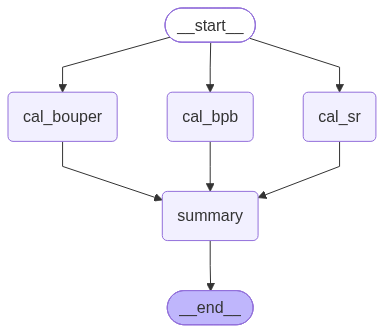

In [25]:
workflow

In [26]:
initial_state = {
    'runs': 100,
    'balls':50,
    'fours':6,
    'six':4
}

workflow.invoke(initial_state)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'six': 4,
 'sr': 200.0,
 'bpb': 5.0,
 'bouper': 48.0,
 'summary': '\n    Strike Rate - 200.0 \n\n    Bolls Per Boundary - 5.0 \n\n    Boundary Percent - 48.0\n    '}